# Etapa 42 — LightGBM global (33 nós) vs ETS nos agregados + MinT

**Pergunta.** Na etapa 41 o LightGBM foi testado só nas UFs (contra o ingênuo). Brasil e regiões seguiram com
ETS amortecido (h 1/4) e ingênuo sazonal (h 8/13). Aqui o LightGBM é treinado como **modelo global sobre os 33 nós**
— séries normalizadas pela média de treino de cada nó, para que Brasil (centenas de casos) e UFs (poucos casos)
convivam no mesmo modelo — e comparado diretamente com a Base V2 em **cada nível e horizonte**.

Em seguida monta-se a **Base V4** (melhor candidato por nível × horizonte, pelo MASE médio nas 58 origens formais),
refaz-se o MinT-OAS não negativo e compara-se com a política atual e a V3.

Candidatos por nível:
* `BASE_V2` — ETS amortecido (agregados, h 1/4), ingênuo sazonal (agregados, h 8/13), ingênuo / ingênuo sazonal (UFs);
* `LGBM_GLOBAL` — este notebook, todos os nós;
* `LGBM_TWEEDIE_UF` — LightGBM só das UFs, da etapa 41.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# funções compartilhadas das etapas 41–43 (hierarquia, métricas, MinT, LightGBM)
from vsr_hier import (COLUNAS, HORIZONTES, ORDEM_NIVEL, RES, anexar_observado, carregar_candidatos, compor_base,
                      ler, metricas, origens, prever_lgbm_global, reconciliar_longo, vetores_erro)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DIR_SAIDA = RES / "etapa_42_lgbm_global_vs_ets"
DIR_SAIDA.mkdir(exist_ok=True)

ORIGENS_CALIB, ORIGENS_FORMAIS = origens()
ORIGENS = ORIGENS_CALIB + ORIGENS_FORMAIS
politica_atual = ler("etapa_37_comparacao_final_hierarquica/previsoes_politica_hierarquica_proposta.csv")
comparacao_41 = ler("etapa_41_modelos_intermitentes_ufs/comparacao_politica_v3_vs_atual.csv")
base_v2 = ler("etapa_30_previsoes_base_hierarquicas_v2/previsoes_base_hierarquicas_v2.csv")
display(base_v2.groupby(["nivel", "horizonte_semanas"])["modelo_base"].unique().unstack())

horizonte_semanas,1,4,8,13
nivel,,,,
BRASIL,[ETS_TENDENCIA_AMORTECIDA_HEURISTICO],[ETS_TENDENCIA_AMORTECIDA_HEURISTICO],[INGENUO_SAZONAL],[INGENUO_SAZONAL]
REGIAO,[ETS_TENDENCIA_AMORTECIDA_HEURISTICO],[ETS_TENDENCIA_AMORTECIDA_HEURISTICO],[INGENUO_SAZONAL],[INGENUO_SAZONAL]
UF,[INGENUO],[INGENUO],[INGENUO_SAZONAL],[INGENUO_SAZONAL]


## 1. LightGBM global com normalização por nó
* Escala do nó na origem = média dos casos no treino (só dados ≤ origem). Atributos e alvo em casos / escala;
  previsão multiplicada de volta. Cada nó pesa igual no ajuste, independentemente do volume.
* Mesmos atributos e hiperparâmetros da etapa 41 (lags 0–3, mesma semana do ano anterior ao alvo, médias móveis 4/8,
  fração de zeros em 8 semanas, semana do ano do alvo) + identificação do nó e do nível como categóricas.
* Estratégia direta: um modelo por horizonte, re-treinado em cada uma das 97 origens (`vsr_hier.prever_lgbm_global`).

In [2]:
ARQUIVO_LGBM = DIR_SAIDA / "previsoes_lgbm_global.csv"
# Backtest é a parte cara: reaproveita o CSV salvo. Apague o arquivo após mudar o modelo.
if ARQUIVO_LGBM.exists():
    lgbm_global = ler(ARQUIVO_LGBM.relative_to(RES))
    print("Backtest carregado de", ARQUIVO_LGBM.name)
else:
    inicio = time.perf_counter()
    lgbm_global = anexar_observado(pd.concat([prever_lgbm_global(o) for o in ORIGENS], ignore_index=True))[COLUNAS]
    print(f"LGBM global: {time.perf_counter() - inicio:.1f} s")
    lgbm_global.to_csv(ARQUIVO_LGBM, index=False)
assert len(lgbm_global) == 97 * 4 * 33 and lgbm_global[["previsao", "casos_observados"]].notna().all().all()

LGBM global: 69.1 s


## 2. Comparação por nível e horizonte (58 origens formais)

In [3]:
CANDIDATOS = carregar_candidatos()

metricas_niveis = pd.concat([metricas(c["FORMAL"], ["nivel", "horizonte_semanas"]).assign(modelo=nome)
                             for nome, c in CANDIDATOS.items()], ignore_index=True)
metricas_niveis.to_csv(DIR_SAIDA / "metricas_candidatos_por_nivel.csv", index=False)
quadro_candidatos = metricas_niveis.pivot_table(index=["nivel", "horizonte_semanas"], columns="modelo", values="mase")
quadro_candidatos = quadro_candidatos.reindex(ORDEM_NIVEL, level=0)
display(quadro_candidatos.style.format("{:.3f}", na_rep="—").highlight_min(axis=1, color="#c6efce"))

# Por região (5 séries), onde o ETS é a base hoje nos horizontes curtos
metricas_regioes = pd.concat([metricas(c["FORMAL"][c["FORMAL"]["nivel"] == "REGIAO"],
                                       ["unidade", "horizonte_semanas"]).assign(modelo=nome)
                              for nome, c in CANDIDATOS.items() if nome != "LGBM_TWEEDIE_UF"])
display(metricas_regioes.pivot_table(index=["unidade", "horizonte_semanas"], columns="modelo", values="mase")
        .style.format("{:.3f}").highlight_min(axis=1, color="#c6efce"))

## 3. Base V4: vencedor por nível × horizonte

In [4]:
VENCEDOR = quadro_candidatos.idxmin(axis=1)
display(VENCEDOR.rename("vencedor").to_frame())
VENCEDOR.rename("vencedor").reset_index().to_csv(DIR_SAIDA / "vencedores_base_v4.csv", index=False)

BASE_V4 = {p: compor_base(CANDIDATOS, VENCEDOR.to_dict(), p) for p in ("FORMAL", "CALIBRACAO")}
assert len(BASE_V4["FORMAL"]) == 58 * 4 * 33 and len(BASE_V4["CALIBRACAO"]) == 39 * 4 * 33

vencedor
nivel  horizonte_semanas                 
BRASIL 1                          BASE_V2
       4                      LGBM_GLOBAL
       8                          BASE_V2
       13                         BASE_V2
REGIAO 1                      LGBM_GLOBAL
       4                      LGBM_GLOBAL
       8                      LGBM_GLOBAL
       13                         BASE_V2
UF     1                  LGBM_TWEEDIE_UF
       4                  LGBM_TWEEDIE_UF
       8                      LGBM_GLOBAL
       13                     LGBM_GLOBAL

## 4. MinT-OAS não negativo (transcrição das etapas 35/36, em `vsr_hier.py`)

In [5]:
# Auto-checagem: o MinT reproduz a política atual (Base V2) em h = 1 e 4
mint_v2, _ = reconciliar_longo(CANDIDATOS["BASE_V2"]["FORMAL"], vetores_erro(CANDIDATOS["BASE_V2"]["CALIBRACAO"]))
checagem = mint_v2.merge(politica_atual, on=["nivel", "unidade", "data_origem", "horizonte_semanas"])
curto = checagem["horizonte_semanas"].isin([1, 4])
assert (checagem.loc[curto, "previsao"] - checagem.loc[curto, "previsao_final"]).abs().max() < 1e-4

# reconciliar_longo já verifica coerência (agregados = S @ UFs) e não negatividade
mint_v4, diag_v4 = reconciliar_longo(BASE_V4["FORMAL"], vetores_erro(BASE_V4["CALIBRACAO"]))
display(diag_v4.groupby("horizonte_semanas").agg(shrinkage_oas=("shrinkage_oas", "first"),
                                                 cortes_com_restricao_ativa=("restricao_ativa", "sum")))

,shrinkage_oas,cortes_com_restricao_ativa
horizonte_semanas,,
1,0.549023,23
4,0.328890,25
8,0.221903,38
13,0.263853,43


## 5. Comparação final: política atual × V3 (etapa 41) × V4

In [6]:
estrategias = {
    "POLITICA_ATUAL": politica_atual.rename(columns={"previsao_final": "previsao"})[COLUNAS],
    "BASE_V4": BASE_V4["FORMAL"],
    "MINT_NN_V4": mint_v4,
}
comparacao = pd.concat([metricas(df, ["nivel", "horizonte_semanas"]).assign(estrategia=nome)
                        for nome, df in estrategias.items()]
                       + [comparacao_41[comparacao_41["estrategia"] == "POLITICA_V3"].drop(columns="delta_mase_vs_atual")],
                       ignore_index=True)

# Política V4: por horizonte, MinT ou base — o que tiver menor MASE médio somando os três níveis
mase_h = comparacao[comparacao["estrategia"].isin(["BASE_V4", "MINT_NN_V4"])].groupby(
    ["horizonte_semanas", "estrategia"])["mase"].mean().unstack()
ESCOLHA_V4 = mase_h.idxmin(axis=1).to_dict()
print("Política V4 por horizonte:", ESCOLHA_V4)
politica_v4 = pd.concat([estrategias[e][estrategias[e]["horizonte_semanas"] == h] for h, e in ESCOLHA_V4.items()])
comparacao = pd.concat([comparacao, metricas(politica_v4, ["nivel", "horizonte_semanas"]).assign(estrategia="POLITICA_V4")],
                       ignore_index=True)
atual = comparacao[comparacao["estrategia"] == "POLITICA_ATUAL"].set_index(["nivel", "horizonte_semanas"])["mase"]
comparacao["delta_mase_vs_atual"] = comparacao["mase"] - atual.reindex(
    pd.MultiIndex.from_frame(comparacao[["nivel", "horizonte_semanas"]])).to_numpy()
comparacao.to_csv(DIR_SAIDA / "comparacao_politicas_atual_v3_v4.csv", index=False)
politica_v4.to_csv(DIR_SAIDA / "previsoes_politica_v4.csv", index=False)

ORDEM_ESTRATEGIAS = ["POLITICA_ATUAL", "POLITICA_V3", "BASE_V4", "MINT_NN_V4", "POLITICA_V4"]
quadro = comparacao.pivot_table(index=["nivel", "horizonte_semanas"], columns="estrategia", values="mase")
quadro = quadro.reindex(ORDEM_NIVEL, level=0)[ORDEM_ESTRATEGIAS]
display(quadro.style.format("{:.3f}").highlight_min(axis=1, color="#c6efce"))

Política V4 por horizonte: {1: 'MINT_NN_V4', 4: 'MINT_NN_V4', 8: 'BASE_V4', 13: 'MINT_NN_V4'}


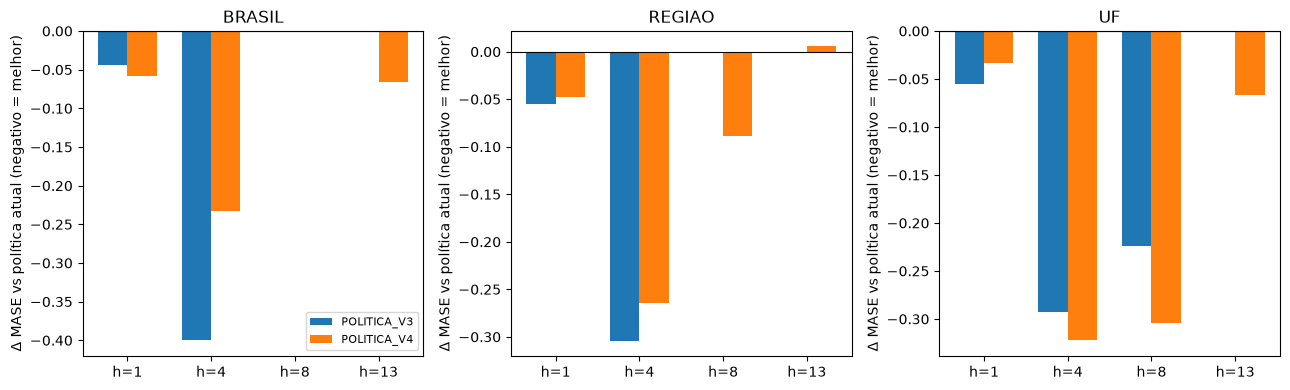

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
outras = ["POLITICA_V3", "POLITICA_V4"]
largura = 0.35
for eixo, nivel in zip(eixos, ORDEM_NIVEL):
    dados = comparacao[comparacao["nivel"] == nivel]
    for k, estrategia in enumerate(outras):
        d = dados[dados["estrategia"] == estrategia].sort_values("horizonte_semanas")
        eixo.bar(np.arange(len(HORIZONTES)) + k * largura, d["delta_mase_vs_atual"], largura, label=estrategia)
    eixo.axhline(0, color="black", linewidth=0.8)
    eixo.set_xticks(np.arange(len(HORIZONTES)) + largura / 2, [f"h={h}" for h in HORIZONTES])
    eixo.set_title(nivel)
    eixo.set_ylabel("Δ MASE vs política atual (negativo = melhor)")
eixos[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(DIR_SAIDA / "delta_mase_politicas_v3_v4.png", dpi=150)
plt.show()

## 6. Leitura
* Seção 2: o LightGBM global supera o ETS amortecido em h=4 no Brasil e nas regiões; em h=1 empatam (Brasil: ETS
  melhor; regiões: LightGBM ligeiramente melhor).
* Seção 5: apesar disso, **depois do MinT a V3 (ETS nos agregados + LightGBM nas UFs) é melhor em h=1 e h=4** — a
  diversidade de modelos entre níveis ajuda a reconciliação. Nos horizontes longos a V4 traz ganhos pequenos.
  Política adotada (etapa 43): V3+MinT em h=1/4, Base V4 em h=8, V4+MinT em h=13.
* Ressalvas: Brasil tem só 58 avaliações por horizonte e regiões 290 — diferenças pequenas de MASE nos agregados
  estão dentro do ruído; a escolha dos vencedores usa as mesmas origens da avaliação (mesmo critério da Base V2,
  levemente otimista); hiperparâmetros do LightGBM não foram ajustados.